<a href="https://colab.research.google.com/github/deekshakb629-design/Miniproject1/blob/main/miniproject01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
df = pd.read_csv('/content/student_info-selected-columns.csv')

In [ ]:
df.head()

,student_id,name,gender,age,grade_level,math_score,reading_score,writing_score,attendance_rate,parent_education
0,S1,Student_1,Other,17,10,74,61,90,94.660002,Master's
1,S2,Student_2,Male,17,12,99,70,91,93.173227,Bachelor's
2,S3,Student_3,Other,17,9,59,60,99,98.631098,PhD
3,S4,Student_4,Other,17,12,70,88,69,96.419620,PhD
4,S5,Student_5,Male,15,9,85,77,94,91.332105,PhD


In [ ]:
df.tail()

,student_id,name,gender,age,grade_level,math_score,reading_score,writing_score,attendance_rate,parent_education
995,S996,Student_996,Female,15,10,76,75,55,94.127440,Bachelor's
996,S997,Student_997,Female,17,12,83,68,98,86.911592,Bachelor's
997,S998,Student_998,Other,16,10,60,77,92,80.139645,PhD
998,S999,Student_999,Other,17,9,94,66,97,88.069619,PhD
999,S1000,Student_1000,Male,17,9,96,92,93,84.695088,PhD


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   student_id        1000 non-null   object 
 1   name              1000 non-null   object 
 2   gender            1000 non-null   object 
 3   age               1000 non-null   int64  
 4   grade_level       1000 non-null   int64  
 5   math_score        1000 non-null   int64  
 6   reading_score     1000 non-null   int64  
 7   writing_score     1000 non-null   int64  
 8   attendance_rate   1000 non-null   float64
 9   parent_education  1000 non-null   object 
dtypes: float64(1), int64(5), object(4)
memory usage: 78.3+ KB


In [ ]:
df.isnull().sum()

,0
student_id,0
name,0
gender,0
age,0
grade_level,0
math_score,0
reading_score,0
writing_score,0
attendance_rate,0
parent_education,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates(inplace= True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.select_dtypes(include = ['int64','float64']).columns

Index(['age', 'grade_level', 'math_score', 'reading_score', 'writing_score',
       'attendance_rate'],
      dtype='object')

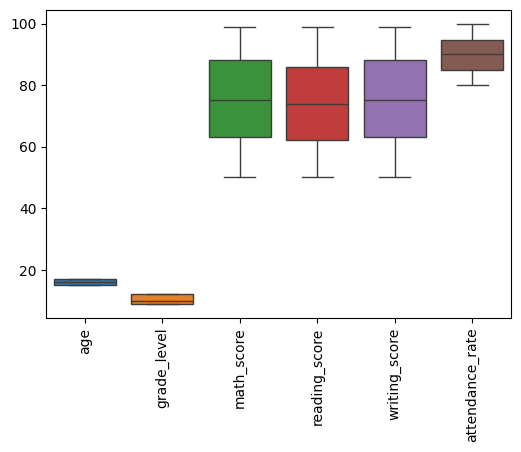

In [27]:

plt.figure(figsize = (6,4))
sns.boxplot(data = df.select_dtypes(include = 'number'))
plt.xticks(rotation = 90)
plt.show()

In [32]:
df.select_dtypes(include = 'object').columns

Index(['student_id', 'name', 'gender', 'parent_education'], dtype='object')

In [35]:
df.drop(['math_score', 'age'], axis = 1,inplace = True)

In [36]:
df.head()

,gender,grade_level,reading_score,writing_score,attendance_rate,parent_education
0,Other,10,61,90,94.660002,Master's
1,Male,12,70,91,93.173227,Bachelor's
2,Other,9,60,99,98.631098,PhD
3,Other,12,88,69,96.419620,PhD
4,Male,9,77,94,91.332105,PhD


In [37]:


from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

for col in df.select_dtypes(include = 'object').columns:
    df[col] = le.fit_transform(df[col])

In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            1000 non-null   int64  
 1   grade_level       1000 non-null   int64  
 2   reading_score     1000 non-null   int64  
 3   writing_score     1000 non-null   int64  
 4   attendance_rate   1000 non-null   float64
 5   parent_education  1000 non-null   int64  
dtypes: float64(1), int64(5)
memory usage: 47.0 KB


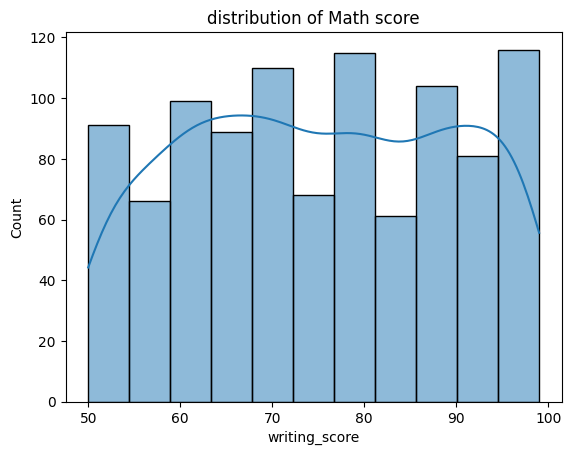

In [41]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df["writing_score"], kde=True)
plt.title("distribution of Math score")
plt.show()

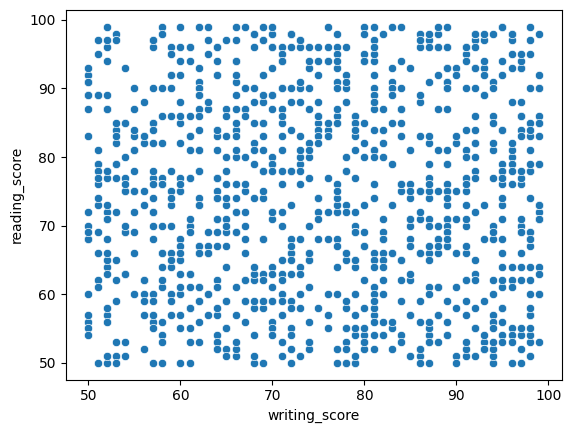

In [43]:
sns.scatterplot(x = 'writing_score', y = 'reading_score', data = df)

plt.show()

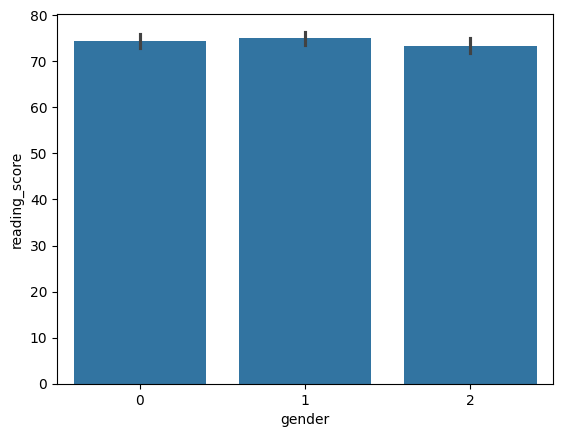

In [46]:
sns.barplot(x = 'gender', y = 'reading_score', data = df)

plt.show()

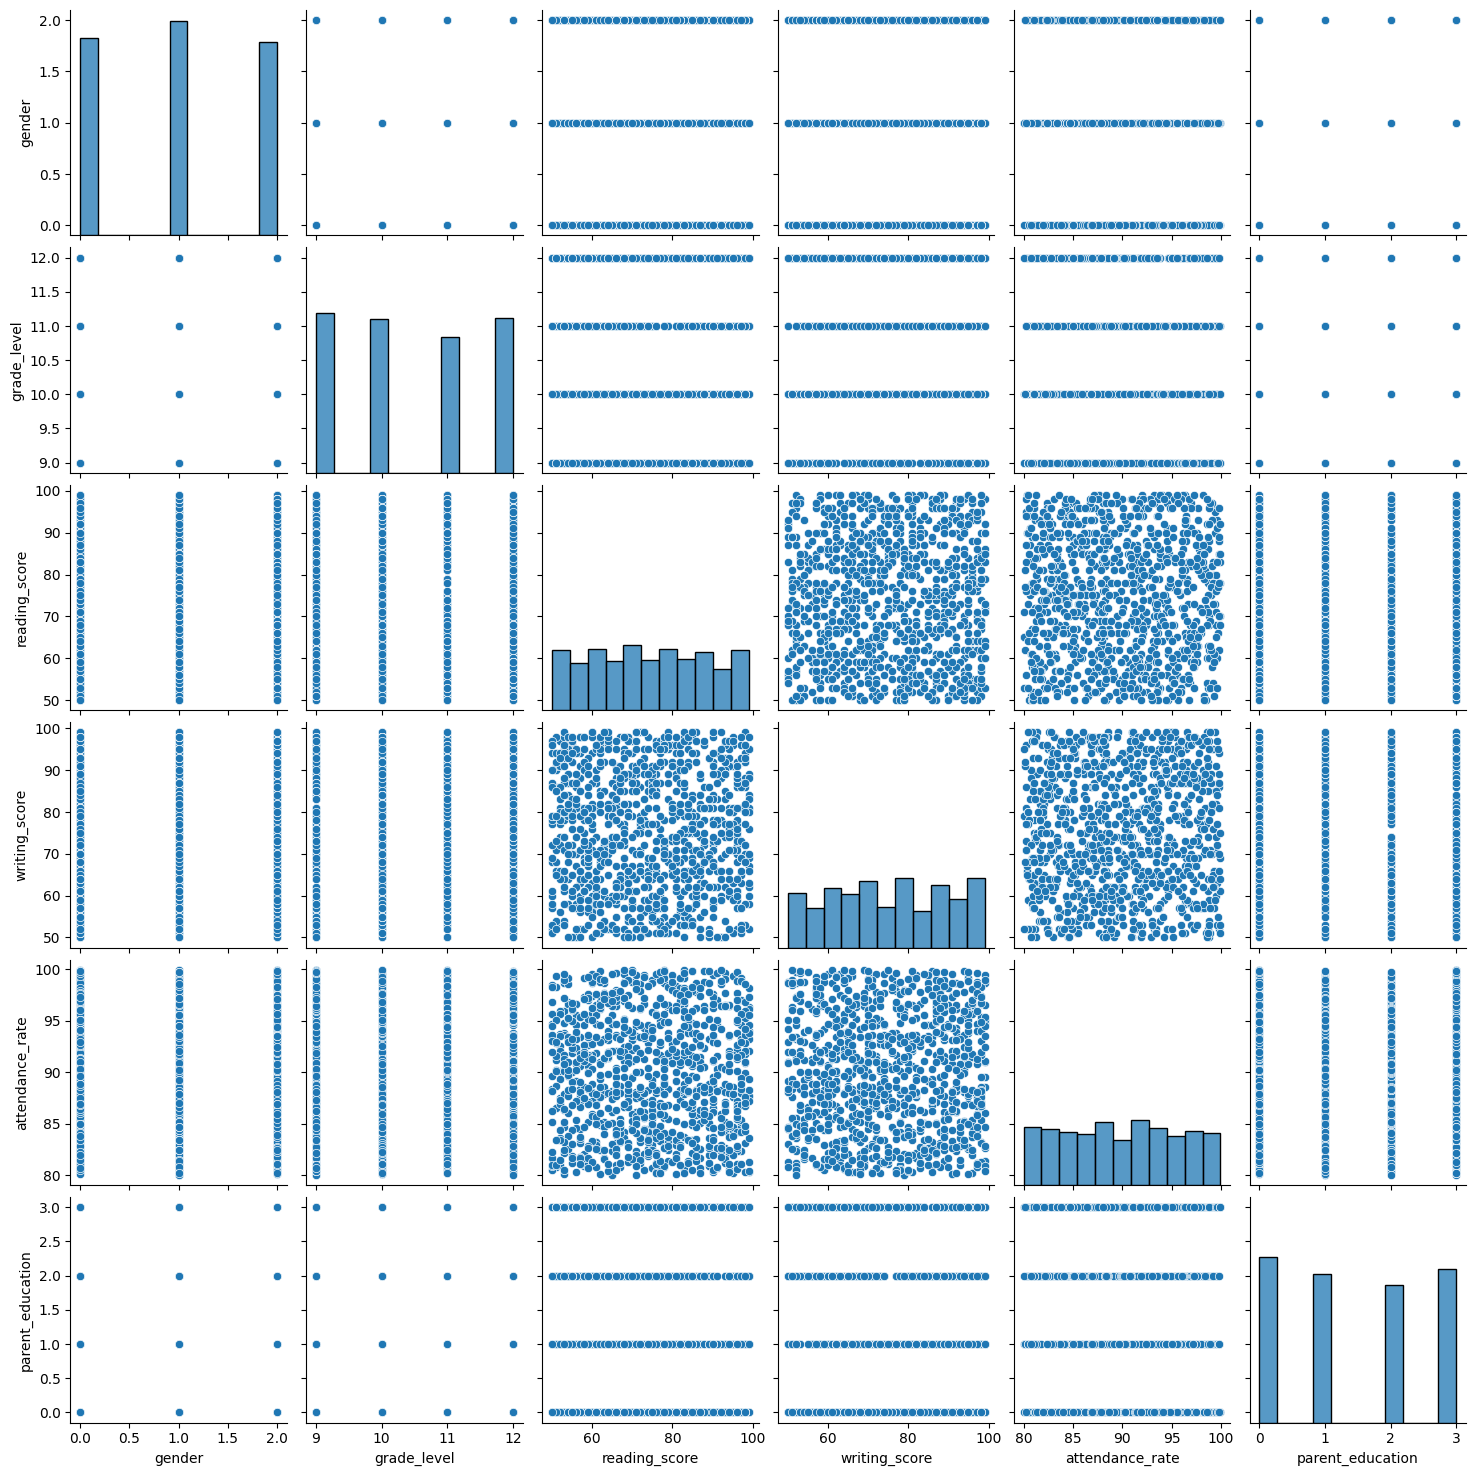

In [47]:
sns.pairplot(df)

plt.show()

In [48]:
corr_matrix = df.select_dtypes(include='number').corr()
corr_matrix

,gender,grade_level,reading_score,writing_score,attendance_rate,parent_education
gender,1.000000,-0.011722,-0.028633,0.028304,-0.015666,0.046037
grade_level,-0.011722,1.000000,0.022188,0.052277,-0.050984,-0.035511
reading_score,-0.028633,0.022188,1.000000,-0.007856,-0.017817,0.032311
writing_score,0.028304,0.052277,-0.007856,1.000000,0.040184,-0.041450
attendance_rate,-0.015666,-0.050984,-0.017817,0.040184,1.000000,-0.013440
parent_education,0.046037,-0.035511,0.032311,-0.041450,-0.013440,1.000000


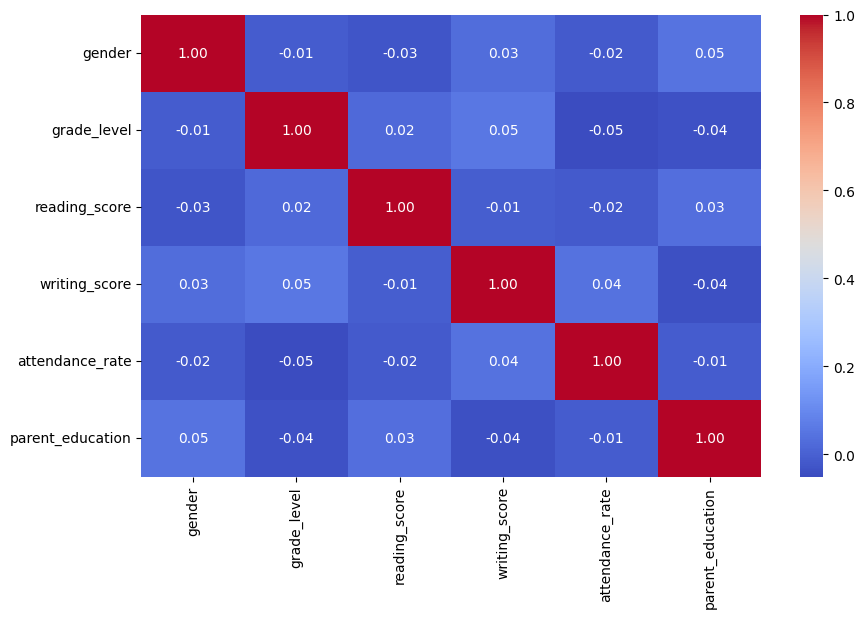

In [50]:
plt.figure(figsize = (10,6))
sns.heatmap(corr_matrix, annot = True, cmap = 'coolwarm', fmt = '.2f')
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

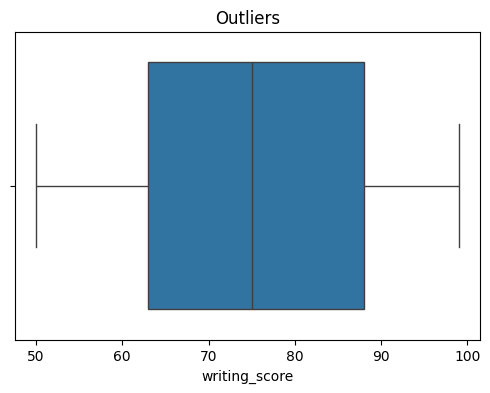

In [29]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['writing_score'])
plt.title("Outliers")
plt.show

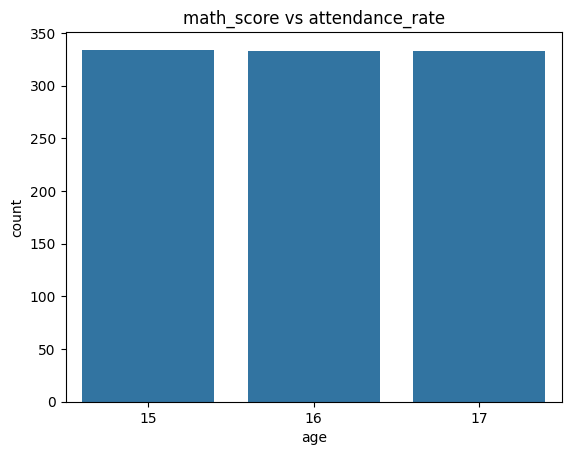

In [31]:
# Univariate analysis
sns.countplot(x = df['age'])
plt.title("math_score vs attendance_rate")
plt.show()

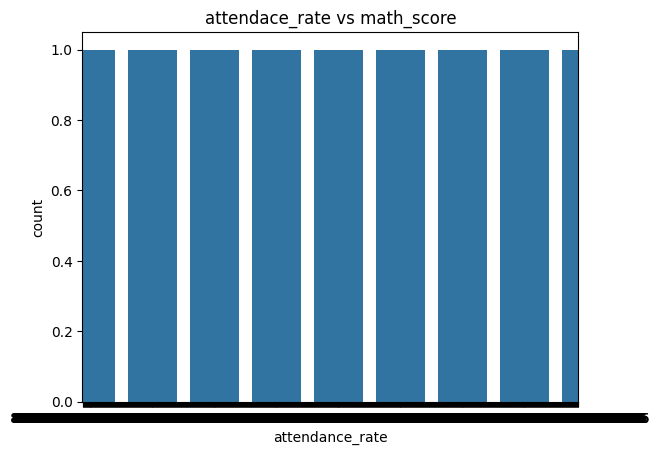

In [23]:
sns.countplot(x=df['attendance_rate'])
plt.title("attendace_rate vs math_score")
plt.show()